<a href="https://colab.research.google.com/github/Sreeja7878/Evaluation_final/blob/main/FAT_2_Cloud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np

# Create 1,00,000 fictional healthcare records
np.random.seed(42)
n = 100000

data = {
    "Patient_ID": range(1, n + 1),
    "Age": np.random.randint(18, 90, n),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Blood_Group": np.random.choice(
        ["A+", "A-", "B+", "B-", "O+", "O-", "AB+", "AB-"], n
    ),
    "Medical_Condition": np.random.choice(
        ["Diabetes", "Asthma", "Cancer", "Hypertension", "Obesity"], n
    ),
    "Admission_Type": np.random.choice(
        ["Emergency", "Elective", "Urgent"], n
    ),
    "Billing_Amount": np.random.randint(5000, 100000, n),
    "Hospital": np.random.choice(
        ["City Hospital", "Green Hospital", "Sunrise Hospital"], n
    )
}

df = pd.DataFrame(data)

# Introduce missing values for the data-cleaning step
df.loc[0:499, "Age"] = np.nan
df.loc[500:999, "Billing_Amount"] = np.nan

# Add 1,000 duplicate rows for the cleaning step
df = pd.concat([df, df.iloc[:1000]], ignore_index=True)

# Save the raw dataset
df.to_csv("healthcare_raw.csv", index=False)

print("Dataset created successfully!")
print("Total records:", len(df))
print(df.head())


Dataset created successfully!
Total records: 101000
   Patient_ID  Age  Gender Blood_Group Medical_Condition Admission_Type  \
0           1  NaN  Female          O-           Obesity      Emergency   
1           2  NaN  Female          O-          Diabetes       Elective   
2           3  NaN  Female         AB+            Cancer       Elective   
3           4  NaN  Female         AB+          Diabetes       Elective   
4           5  NaN  Female         AB+          Diabetes      Emergency   

   Billing_Amount          Hospital  
0         77852.0  Sunrise Hospital  
1         37276.0  Sunrise Hospital  
2         20476.0  Sunrise Hospital  
3         69447.0     City Hospital  
4          8057.0     City Hospital  


In [ ]:

import os

print(os.listdir("/content"))


['.config', 'healthcare_raw.csv', 'sample_data']


In [ ]:
from google.colab import files
files.download("healthcare_raw.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd

# Load the dataset
df = pd.read_csv("healthcare_raw.csv")

print("Before cleaning:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing ages with the average age
df["Age"] = df["Age"].fillna(df["Age"].mean())

# Fill missing billing amounts with the average billing
df["Billing_Amount"] = df["Billing_Amount"].fillna(
    df["Billing_Amount"].mean()
)

# Save the cleaned dataset
df.to_csv("healthcare_cleaned.csv", index=False)

print("After cleaning:", df.shape)
print("Missing ages:", df["Age"].isnull().sum())
print("Missing billing:", df["Billing_Amount"].isnull().sum())
print("Cleaning completed successfully!")



Before cleaning: (101000, 8)
After cleaning: (100000, 8)
Missing ages: 0
Missing billing: 0
Cleaning completed successfully!


In [ ]:

from google.colab import files
files.download("healthcare_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd

# Load the cleaned dataset
df = pd.read_csv("healthcare_cleaned.csv")

# 1. Total number of patients
print("Total patients:", len(df))

# 2. Average patient age
print("Average age:", round(df["Age"].mean(), 2))

# 3. Average hospital bill
print("Average hospital bill:", round(df["Billing_Amount"].mean(), 2))

# 4. Number of patients by medical condition
print("\nPatients by medical condition:")
print(df["Medical_Condition"].value_counts())

# 5. Number of patients by hospital
print("\nPatients by hospital:")
print(df["Hospital"].value_counts())


Total patients: 100000
Average age: 53.35
Average hospital bill: 52511.32

Patients by medical condition:
Medical_Condition
Cancer          20188
Diabetes        20164
Obesity         19938
Asthma          19933
Hypertension    19777
Name: count, dtype: int64

Patients by hospital:
Hospital
Sunrise Hospital    33455
Green Hospital      33320
City Hospital       33225
Name: count, dtype: int64


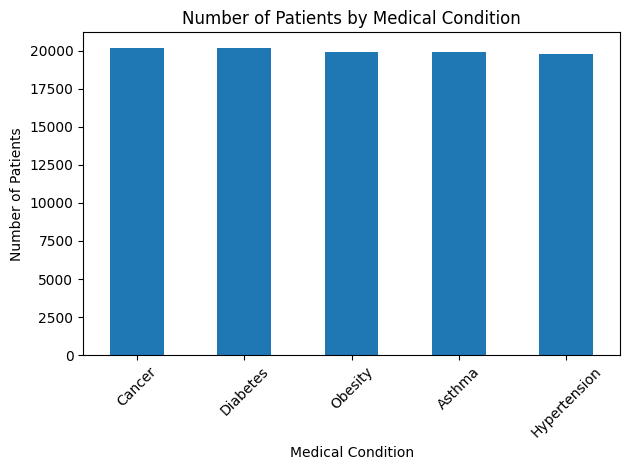

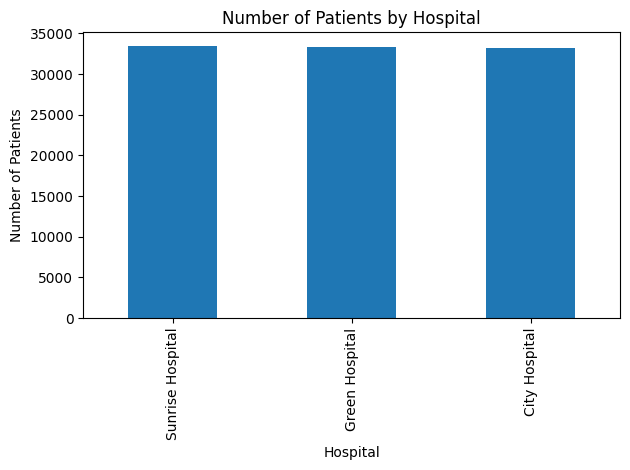

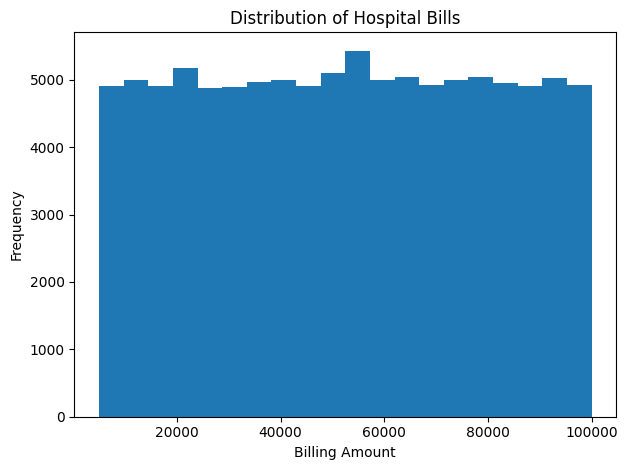

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset
df = pd.read_csv("healthcare_cleaned.csv")

# Chart 1: Patients by medical condition
df["Medical_Condition"].value_counts().plot(kind="bar")
plt.title("Number of Patients by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Chart 2: Patients by hospital
df["Hospital"].value_counts().plot(kind="bar")
plt.title("Number of Patients by Hospital")
plt.xlabel("Hospital")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

# Chart 3: Distribution of hospital bills
df["Billing_Amount"].plot(kind="hist", bins=20)
plt.title("Distribution of Hospital Bills")
plt.xlabel("Billing Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
